# VisionOps — Dataset exploration

This notebook explores class distributions and sample images. Training logic stays in `src/visionops`.

In [5]:
from pathlib import Path
from collections import Counter
from PIL import Image
import matplotlib.pyplot as plt

def find_project_root():
    candidates = [Path.cwd(), *Path.cwd().parents, Path('/home/walid/Documents/R&D/VisionOps')]
    for candidate in candidates:
        if (candidate / 'data' / 'raw').exists():
            return candidate
    raise FileNotFoundError('Could not locate the VisionOps project root.')

PROJECT_ROOT = find_project_root()
DATASETS = {
    'intel_train': PROJECT_ROOT / 'data/raw/seg_train/seg_train',
    'eurosat': PROJECT_ROOT / 'data/raw/eurosat/eurosat/2750',
}
print('Project root:', PROJECT_ROOT)

Project root: /home/walid/Documents/R&D/VisionOps


In [6]:
def image_paths(root):
    extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}
    return {
        class_dir.name: sorted(
            path for path in class_dir.rglob('*')
            if path.is_file() and path.suffix.lower() in extensions
        )
        for class_dir in sorted(root.iterdir()) if class_dir.is_dir()
    }

for name, root in DATASETS.items():
    counts = {label: len(paths) for label, paths in image_paths(root).items()}
    print(name, counts)

intel_train {'buildings': 2191, 'forest': 2271, 'glacier': 2404, 'mountain': 2512, 'sea': 2274, 'street': 2382}
eurosat {'AnnualCrop': 3000, 'Forest': 3000, 'HerbaceousVegetation': 3000, 'Highway': 2500, 'Industrial': 2500, 'Pasture': 2000, 'PermanentCrop': 2500, 'Residential': 3000, 'River': 2500, 'SeaLake': 3000}


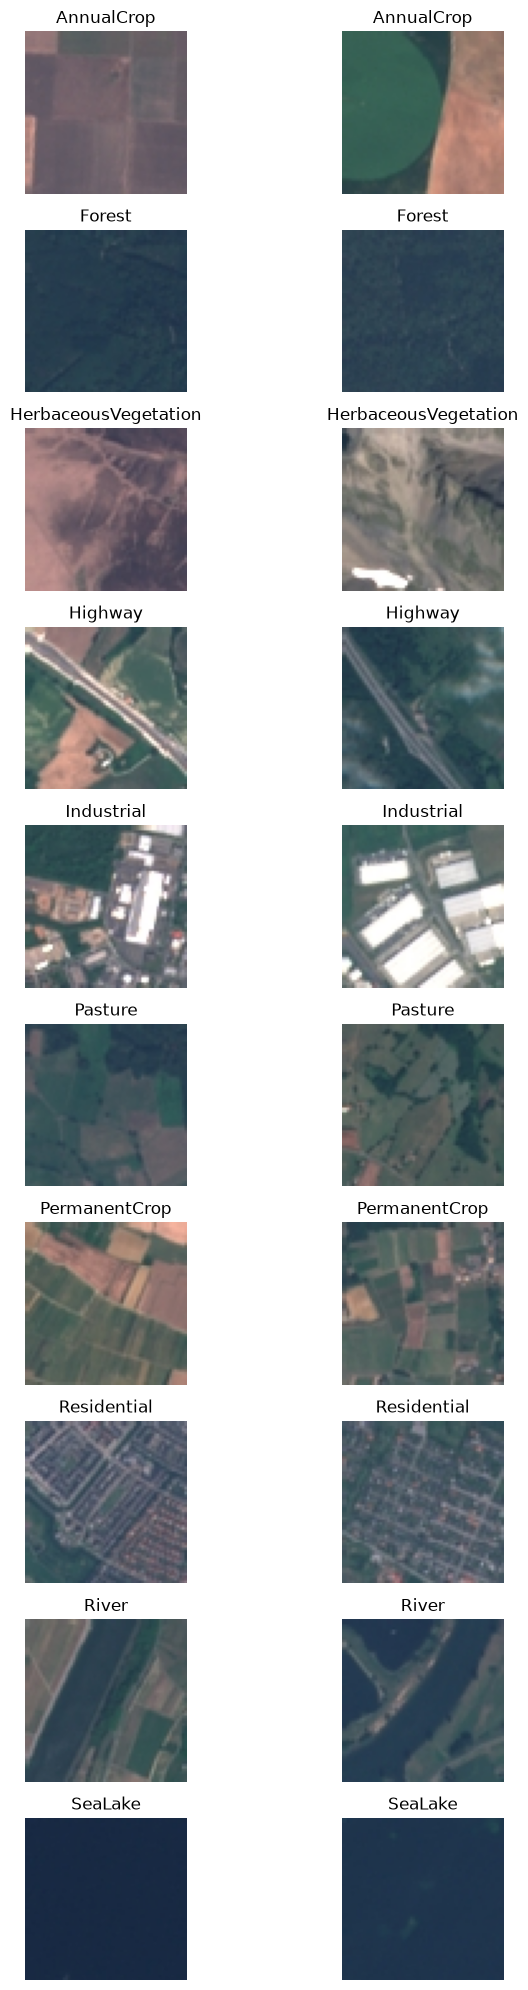

In [7]:
def show_examples(root, samples_per_class=2):
    classes = image_paths(root)
    fig, axes = plt.subplots(len(classes), samples_per_class, figsize=(8, 2 * len(classes)))
    axes = axes.reshape(len(classes), samples_per_class)
    for row, (label, paths) in enumerate(classes.items()):
        for col, path in enumerate(paths[:samples_per_class]):
            axes[row, col].imshow(Image.open(path))
            axes[row, col].set_title(label)
            axes[row, col].axis('off')
    plt.tight_layout()

show_examples(DATASETS['eurosat'])